# Bài tập Thực hành 2: Huấn luyện Mô hình Phân loại Tín hiệu Âm thanh với 1D CNN (Audio Classification)

Trong bài tập này, các bạn sẽ thực hành xây dựng quy trình Deep Learning phân loại giọng nói từ dữ liệu sóng âm thanh thời gian (Raw Waveform) sử dụng mạng tích phân 1 chiều (**1D CNN**) trên bộ dữ liệu **Speech Commands**:

1. **Tải và Đọc bộ dữ liệu bên ngoài**: Tải bộ dữ liệu `Speech Commands` từ TensorFlow Storage, giải nén và nạp các file âm thanh `.wav` của 4 lệnh giọng nói (`go`, `stop`, `yes`, `no`).
2. **Chuẩn bị Dữ liệu dạng Sóng 1D (Raw Waveform)**: Đọc tín hiệu thời gian dạng sóng 1D (độ dài 16,000 samples = 1.0s ở tần số lấy mẫu 16kHz) không qua biến đổi phổ STFT.
3. **Tiền xử lý & Đóng gói dữ liệu**: Định hình dữ liệu dạng tensor 3D `(batch_size, 1, sequence_length)` cho PyTorch 1D CNN, phân chia tập Train/Test và đóng gói vào PyTorch `DataLoader`.
4. **Xây dựng Mô hình (Model Architecture)**: Định nghĩa mạng tích phân 1 chiều (**1D CNN**) bằng PyTorch (`nn.Conv1d`, `nn.BatchNorm1d`, `nn.MaxPool1d`, `nn.AdaptiveAvgPool1d`, `nn.Linear`).
5. **Huấn luyện Mô hình (Training Loop)**: Cấu hình Loss Function (`CrossEntropyLoss`), Optimizer (`Adam`) và viết vòng lặp huấn luyện qua nhiều epochs.
6. **Đánh giá & Trực quan hóa**: Vẽ đồ thị đường cong học tập (Learning curves), báo cáo phân loại (Classification Report) và ma trận nhầm lẫn (Confusion Matrix).
7. **Câu hỏi thảo luận**: Trả lời câu hỏi phân tích về những hạn chế cốt lõi của mô hình 1D CNN khi xử lý trực tiếp tín hiệu dạng sóng thời gian (Raw Waveform).


## 1. Import các thư viện cần thiết
Chạy cell dưới đây để nạp các thư viện cơ bản cho đọc file/tải dữ liệu (`urllib`, `zipfile`, `glob`), xử lý tín hiệu âm thanh (`librosa`), học sâu (`torch`), tiền xử lý/đánh giá (`sklearn`) và trực quan hóa (`matplotlib`, `seaborn`).


In [1]:
# Chạy lệnh này trong terminal nếu chưa cài đặt thư viện:
# pip install torch librosa numpy matplotlib scikit-learn seaborn

import os
import glob
import zipfile
import urllib.request
import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình seed ngẫu nhiên để kết quả có tính tái lập (reproducible)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Librosa version: {librosa.__version__}")
print(f"Using device: {device}")


PyTorch version: 2.9.1+cu128
Librosa version: 1.0.0
Using device: cuda


## 2. Tải và Nạp Bộ Dữ liệu Âm thanh Bên ngoài (Speech Commands Dataset)
Chúng ta sẽ tải bộ dữ liệu lệnh giọng nói thực tế **Mini Speech Commands Dataset** từ nguồn bên ngoài.
Bộ dữ liệu gồm 4 lớp từ lệnh giọng nói: `go`, `stop`, `yes`, `no`. Mỗi mẫu âm thanh có tần số lấy mẫu \(sr = 16000\) Hz và thời lượng 1.0 giây (tương ứng 16,000 mẫu số liệu dạng sóng 1D).


In [2]:
# TODO 1: Tải bộ dữ liệu, giải nén và nạp các file âm thanh .wav
url = 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
zip_path = 'mini_speech_commands.zip'
extract_dir = 'dataset_speech_commands'

# Tái sử dụng dataset đã có ở ngày 54 nếu đang chạy trong repo này.
shared_extract_dir = os.path.join('..', 'day 54 25-8-2026', 'dataset_speech_commands')
if not os.path.exists(extract_dir) and os.path.exists(shared_extract_dir):
    extract_dir = shared_extract_dir

if not os.path.exists(zip_path) and not os.path.exists(extract_dir):
    print("Đang tải dữ liệu Speech Commands từ internet...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_dir):
    print("Đang giải nén bộ dữ liệu...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

dataset_dir = os.path.join(extract_dir, 'mini_speech_commands')
target_classes = ['go', 'stop', 'yes', 'no']
max_samples_per_class = 150

X_audio = []
y_labels = []

for label, class_name in enumerate(target_classes):
    wav_files = sorted(glob.glob(os.path.join(dataset_dir, class_name, '*.wav')))
    for wav_path in wav_files[:max_samples_per_class]:
        audio, _ = librosa.load(wav_path, sr=16000, mono=True, duration=1.0)
        if len(audio) < 16000:
            audio = np.pad(audio, (0, 16000 - len(audio)))
        else:
            audio = audio[:16000]
        X_audio.append(audio)
        y_labels.append(label)

print(f"Tổng số mẫu âm thanh đã nạp: {len(X_audio)}")
print(f"Độ dài mỗi mẫu âm thanh: {len(X_audio[0])} samples")

D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tổng số mẫu âm thanh đã nạp: 600
Độ dài mỗi mẫu âm thanh: 16000 samples


## 3. Tiền xử lý dữ liệu sóng & Tạo PyTorch DataLoader
1. Chuyển `X_audio` thành numpy array và định hình lại theo chuẩn input của PyTorch 1D CNN: **`(batch_size, num_channels, sequence_length)`** -> **`(N, 1, 16000)`**.
2. Chia dữ liệu thành tập **Train (80%)** và tập **Test (20%)** giữ nguyên tỉ lệ lớp (`stratify=y_labels`, `random_state=SEED`).
3. Chuyển mảng NumPy thành `torch.Tensor` (`float32` cho X, `long` cho y).
4. Đóng gói vào `TensorDataset` và `DataLoader` với `batch_size = 16` (`shuffle=True` cho tập Train).


In [3]:
# TODO 2: Định hình lại dữ liệu, phân chia Train/Test và tạo DataLoader
X_audio = np.array(X_audio, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int64)
X_audio = np.expand_dims(X_audio, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X_audio,
    y_labels,
    test_size=0.2,
    random_state=SEED,
    stratify=y_labels
)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Kích thước tập Train (X_train): {X_train.shape}")
print(f"Kích thước tập Test (X_test): {X_test.shape}")

Kích thước tập Train (X_train): torch.Size([480, 1, 16000])
Kích thước tập Test (X_test): torch.Size([120, 1, 16000])


## 4. Xây dựng Kiến trúc Mô hình 1D CNN (AudioCNN1D)
Thiết kế mạng nơ-ron tích phân 1 chiều (1D CNN) thích hợp để tự động trích xuất đặc trưng từ dạng sóng âm thanh 1D (độ dài 16,000 mẫu):
- **Convolutional Feature Extractor**:
  - **Block 1**: `Conv1d(1, 16, kernel_size=64, stride=4, padding=30)` -> `BatchNorm1d(16)` -> `ReLU()` -> `MaxPool1d(kernel_size=4)`
  - **Block 2**: `Conv1d(16, 32, kernel_size=32, stride=2, padding=15)` -> `BatchNorm1d(32)` -> `ReLU()` -> `MaxPool1d(kernel_size=4)`
  - **Block 3**: `Conv1d(32, 64, kernel_size=16, stride=2, padding=7)` -> `BatchNorm1d(64)` -> `ReLU()` -> `MaxPool1d(kernel_size=2)`
  - **Block 4**: `Conv1d(64, 128, kernel_size=8, stride=1, padding=4)` -> `BatchNorm1d(128)` -> `ReLU()` -> `AdaptiveAvgPool1d(1)`
- **Classifier Header**:
  - `Flatten()` -> `Linear(128, 64)` -> `ReLU()` -> `Dropout(0.3)` -> `Linear(64, num_classes=4)`.


In [4]:
# TODO 3: Định nghĩa lớp mô hình AudioCNN1D kế thừa từ nn.Module
class AudioCNN1D(nn.Module):
    def __init__(self, num_classes=4):
        super(AudioCNN1D, self).__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=64, stride=4, padding=30),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(16, 32, kernel_size=32, stride=2, padding=15),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(32, 64, kernel_size=16, stride=2, padding=7),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=8, stride=1, padding=4),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = AudioCNN1D(num_classes=4).to(device)
print(model)

AudioCNN1D(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(64,), stride=(4,), padding=(30,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(32,), stride=(2,), padding=(15,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(16,), stride=(2,), padding=(7,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv1d(64, 128, kernel_size=(8,), stride=(1,), padding=(4,))
    (13): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
   

## 5. Cấu hình Loss Function & Optimizer
Với bài toán phân loại đa lớp:
- **Loss Function**: `nn.CrossEntropyLoss()`
- **Optimizer**: `optim.Adam()` với `learning_rate = 0.001`.


In [5]:
# TODO 4: Khởi tạo Criterion (Loss Function) và Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Hàm mất mát và thuật toán tối ưu đã khởi tạo thành công.")

Hàm mất mát và thuật toán tối ưu đã khởi tạo thành công.


## 6. Huấn luyện Mô hình (Training Loop)
Thực hiện huấn luyện mô hình qua **25 Epochs**.
Ghi lại lịch sử loss và accuracy trên cả 2 tập Train và Test sau mỗi epoch.


In [6]:
# TODO 5: Viết vòng lặp huấn luyện mô hình qua 25 Epochs
epochs = 25
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = train_correct / len(train_loader.dataset)

    model.eval()
    running_loss = 0.0
    test_correct = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()

    test_loss = running_loss / len(test_loader.dataset)
    test_acc = test_correct / len(test_loader.dataset)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} - "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} - "
        f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}"
    )

Epoch 01/25 - Train Loss: 1.3256, Train Acc: 0.3833 - Test Loss: 1.3634, Test Acc: 0.2750
Epoch 02/25 - Train Loss: 1.1159, Train Acc: 0.5667 - Test Loss: 1.2393, Test Acc: 0.3833


Epoch 03/25 - Train Loss: 0.9047, Train Acc: 0.6417 - Test Loss: 1.0150, Test Acc: 0.5750
Epoch 04/25 - Train Loss: 0.7418, Train Acc: 0.7188 - Test Loss: 0.8306, Test Acc: 0.7333


Epoch 05/25 - Train Loss: 0.5990, Train Acc: 0.8063 - Test Loss: 0.7955, Test Acc: 0.7083
Epoch 06/25 - Train Loss: 0.5040, Train Acc: 0.8187 - Test Loss: 0.9451, Test Acc: 0.6167


Epoch 07/25 - Train Loss: 0.4421, Train Acc: 0.8500 - Test Loss: 0.5860, Test Acc: 0.8500
Epoch 08/25 - Train Loss: 0.3944, Train Acc: 0.8646 - Test Loss: 0.5842, Test Acc: 0.8250


Epoch 09/25 - Train Loss: 0.4083, Train Acc: 0.8604 - Test Loss: 0.5205, Test Acc: 0.8583
Epoch 10/25 - Train Loss: 0.4121, Train Acc: 0.8562 - Test Loss: 0.5826, Test Acc: 0.8000


...

Epoch 17/25 - Train Loss: 0.2581, Train Acc: 0.9146 - Test Loss: 0.6472, Test Acc: 0.8000


Epoch 18/25 - Train Loss: 0.2311, Train Acc: 0.9271 - Test Loss: 0.4451, Test Acc: 0.8750
Epoch 19/25 - Train Loss: 0.1911, Train Acc: 0.9313 - Test Loss: 0.5764, Test Acc: 0.8250


Epoch 20/25 - Train Loss: 0.2087, Train Acc: 0.9271 - Test Loss: 1.3927, Test Acc: 0.6000
Epoch 21/25 - Train Loss: 0.2432, Train Acc: 0.9146 - Test Loss: 0.9466, Test Acc: 0.6667


Epoch 22/25 - Train Loss: 0.2428, Train Acc: 0.9250 - Test Loss: 0.4638, Test Acc: 0.8333
Epoch 23/25 - Train Loss: 0.1693, Train Acc: 0.9542 - Test Loss: 0.3565, Test Acc: 0.9167


Epoch 24/25 - Train Loss: 0.1511, Train Acc: 0.9583 - Test Loss: 0.2534, Test Acc: 0.9167
Epoch 25/25 - Train Loss: 0.1642, Train Acc: 0.9437 - Test Loss: 0.3841, Test Acc: 0.8667


## 7. Đánh giá Mô hình & Trực quan hóa Kết quả
1. Vẽ biểu đồ diễn biến **Loss** và **Accuracy** trên 2 tập Train/Test theo Epochs.
2. Hiển thị **Classification Report** (Precision, Recall, F1-score) cho 4 lớp từ lệnh giọng nói (`go`, `stop`, `yes`, `no`).
3. Vẽ **Ma trận nhầm lẫn (Confusion Matrix)** bằng Heatmap của `seaborn`.


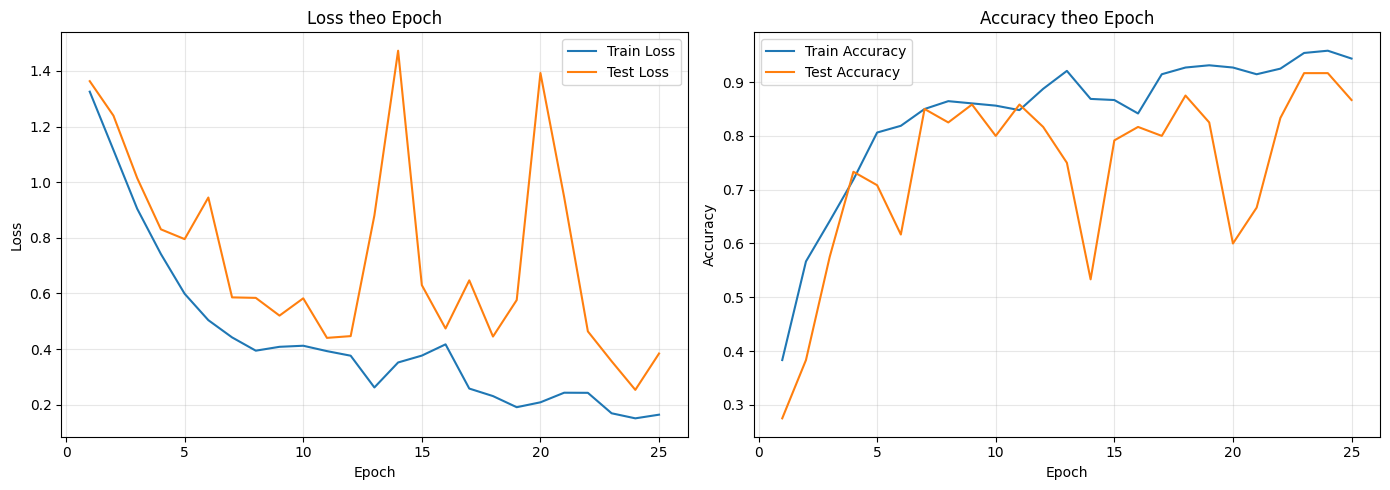

Độ chính xác Test cuối cùng: 0.8667
              precision    recall  f1-score   support

          go       0.96      0.73      0.83        30
        stop       0.89      0.80      0.84        30
         yes       0.94      0.97      0.95        30
          no       0.74      0.97      0.84        30

    accuracy                           0.87       120
   macro avg       0.88      0.87      0.87       120
weighted avg       0.88      0.87      0.87       120



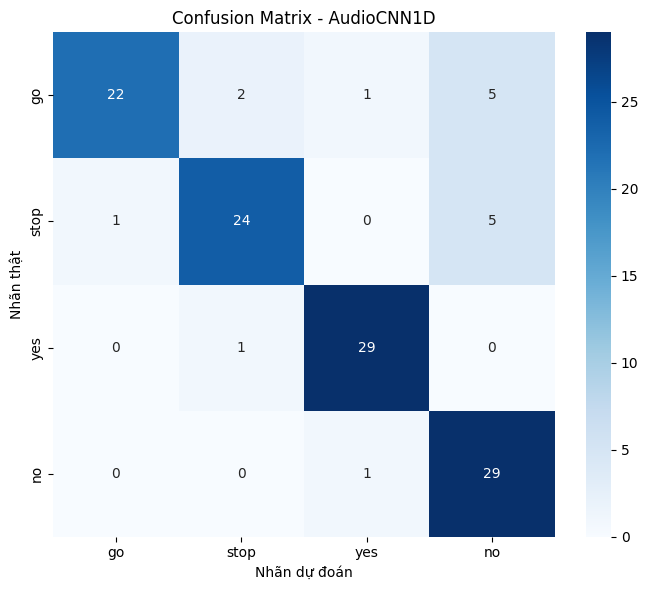

In [7]:
# TODO 6: Vẽ đồ thị quá trình huấn luyện và ma trận nhầm lẫn
epoch_numbers = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epoch_numbers, train_losses, label='Train Loss')
axes[0].plot(epoch_numbers, test_losses, label='Test Loss')
axes[0].set_title('Loss theo Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epoch_numbers, train_accs, label='Train Accuracy')
axes[1].plot(epoch_numbers, test_accs, label='Test Accuracy')
axes[1].set_title('Accuracy theo Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

model.eval()
all_predictions = []
all_labels = []
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs.to(device))
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(f"Độ chính xác Test cuối cùng: {test_accs[-1]:.4f}")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=target_classes,
    zero_division=0
))

cm = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_classes, yticklabels=target_classes)
plt.title('Confusion Matrix - AudioCNN1D')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thật')
plt.tight_layout()
plt.show()

## 8. Câu hỏi thảo luận & Mở rộng

**Câu hỏi:** Hãy phân tích những **hạn chế chính** của việc huấn luyện mô hình 1D CNN xử lý trực tiếp tín hiệu dạng sóng âm thanh thời gian (Raw Waveform) so với việc trích xuất đặc trưng phổ thời gian - tần số (như STFT Spectrogram hay MFCC)?

**Trả lời:**

- Raw waveform có 16.000 giá trị cho mỗi giây nhưng chưa biểu diễn trực tiếp thành phần tần số. Vì vậy 1D CNN phải tự học cả bộ lọc tần số lẫn đặc trưng phân loại từ dữ liệu, thường cần nhiều mẫu và thời gian huấn luyện hơn.
- Dạng sóng thay đổi mạnh khi tín hiệu bị lệch thời gian, đổi pha, thay đổi âm lượng hoặc có nhiễu. Hai cách phát âm cùng một từ có thể tạo waveform khá khác nhau dù nội dung giống nhau.
- STFT và MFCC đã gom thông tin theo cả thời gian và tần số. Các formant, dải năng lượng và cấu trúc âm tiết vì thế rõ hơn, giúp mô hình nhỏ học dễ hơn và thường ổn định hơn với dữ liệu ít.
- Ưu điểm của raw waveform là giữ toàn bộ thông tin gốc và cho phép mô hình tự học đặc trưng phù hợp. Tuy nhiên lợi thế này thường rõ hơn khi có dữ liệu lớn và mô hình đủ mạnh.